In [2]:
import torch 
from torch import nn, Tensor

import matplotlib.pyplot as plt

In [ ]:
class Flow(nn.Module):
    def __init__(self, dim: int = 1, h: int = 64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(dim + 1, h), # (t, x_t)
            nn.ELU(),
            nn.Linear(h, h),
            nn.ELU(),
            nn.Linear(h, h), 
            nn.ELU(),
            nn.Linear(h, dim)
        )
    
    def forward(self, t: Tensor, x_t: Tensor) -> Tensor:
        return self.net(torch.cat((t, x_t), -1)) # v_x
    
    def step(self, x_t: Tensor, t_start: Tensor, t_end: Tensor) -> Tensor:
        t_start = t_start.view(1, 1).expand(x_t.shape[0], 1)
        delta = t_end - t_start
        # rk2 solver
        return x_t + delta * self(t=t_start + delta / 2, x_t= x_t + self(x_t=x_t, t=t_start) * delta / 2)

# Training

In [ ]:
flow = Flow().cuda()
N = 10000
optimizer = torch.optim.Adam(flow.parameters(), 1e-2)
loss_fn = nn.MSELoss()

for _ in range(10000):
    x_0 = torch.rand(N, 1).cuda()
    x_1 = torch.randn(N, 1).cuda()
    t = torch.rand(N, 1).cuda()
    
    x_t = (1 - t) * x_0 + t * x_1
    dx_t = x_1 - x_0
    
    optimizer.zero_grad()
    loss_fn(flow(t=t, x_t=x_t), dx_t).backward()
    optimizer.step()

# Sampling

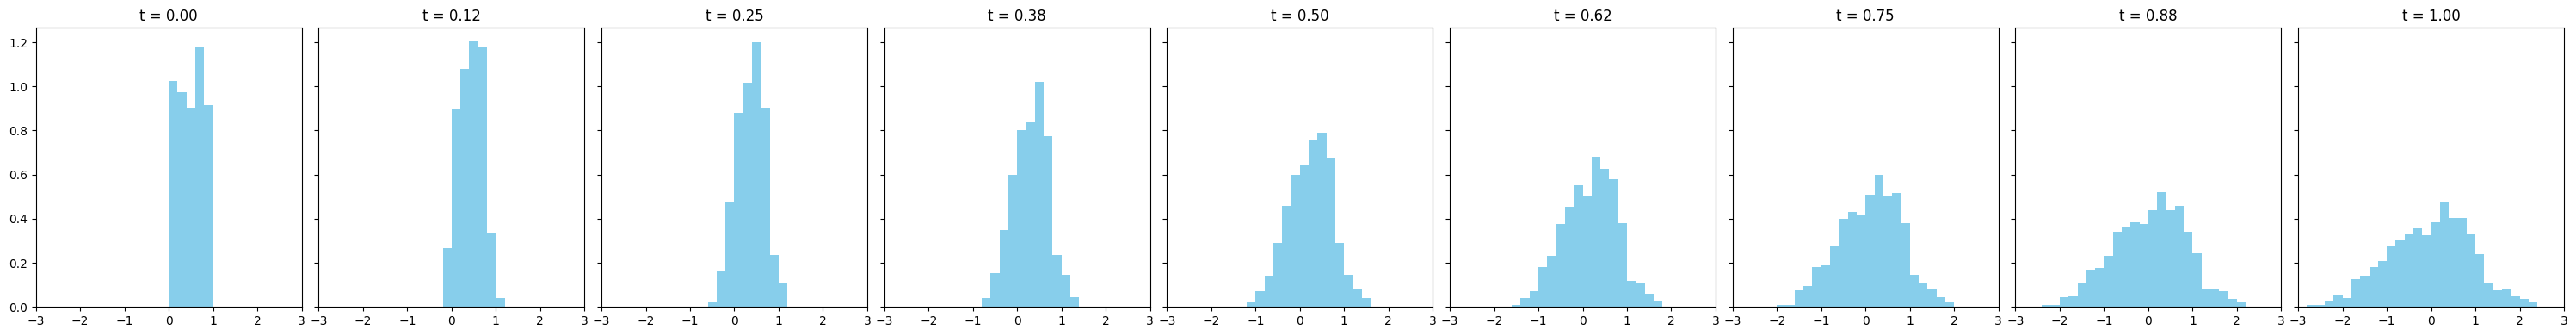

In [18]:
flow = flow.cpu()
N = 1000
x = torch.rand(N, 1)  # (300, 1)
n_steps = 8
time_steps = torch.linspace(0, 1.0, n_steps + 1)

fig, axes = plt.subplots(1, n_steps + 1, figsize=(30, 4), sharey=True)

# t=0 的分布
axes[0].hist(x.detach().squeeze().numpy(), bins=30, range=(-3, 3), color='skyblue', density=True)
axes[0].set_title(f't = {time_steps[0]:.2f}')
axes[0].set_xlim(-3.0, 3.0)

# 后续每一步的分布
for i in range(n_steps):
    x = flow.step(x_t=x, t_start=time_steps[i], t_end=time_steps[i + 1])
    axes[i + 1].hist(x.detach().squeeze().numpy(), bins=30, range=(-3, 3), color='skyblue', density=True)
    axes[i + 1].set_title(f't = {time_steps[i + 1]:.2f}')
    axes[i + 1].set_xlim(-3.0, 3.0)

plt.tight_layout()
plt.show()

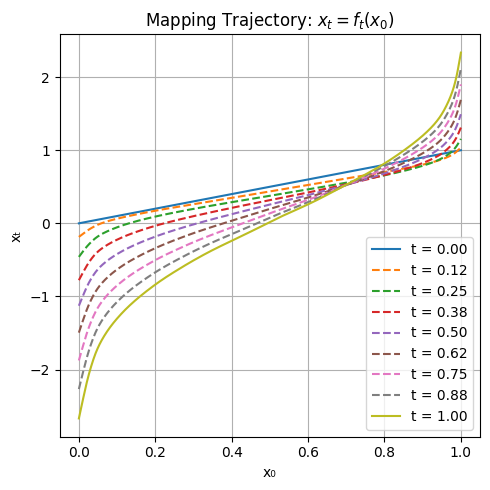

In [17]:

# 初始化输入：均匀采样的一维输入点
x0 = torch.linspace(0, 1, 3000).unsqueeze(1)  # shape (300, 1)
n_steps = 8
time_steps = torch.linspace(0, 1.0, n_steps + 1)

# 存储每个时间步的 x_t
xt_list = [x0.detach().clone()]

x = x0.clone()
for i in range(n_steps):
    x = flow.step(x_t=x, t_start=time_steps[i], t_end=time_steps[i + 1])
    xt_list.append(x.detach().clone())

# 可视化：每条线表示一个 t 的映射函数
plt.figure(figsize=(5, 5))
for i, xt in enumerate(xt_list):
    t = time_steps[i]
    if i == 0 or i == n_steps:
        plt.plot(x0.squeeze(), xt.squeeze(), label=f"t = {t:.2f}")
    else:
        plt.plot(x0.squeeze(), xt.squeeze(), '--', label=f"t = {t:.2f}")

# # 恒等线 y = x₀
# plt.plot(x0.squeeze(), x0.squeeze(), '--', color='gray', label='y = x')

plt.xlabel("x₀")
plt.ylabel("xₜ")
plt.title("Mapping Trajectory: $x_t = f_t(x_0)$")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


Compare to the Inverse CDF of normal distribution. (There's no closed form expression for the inverse cdf of a normal)

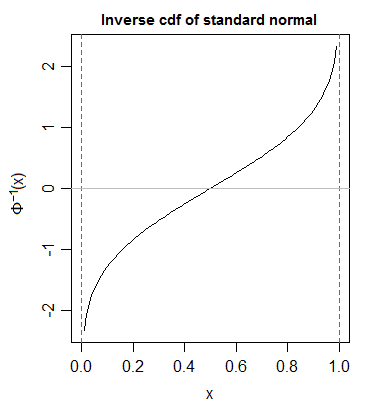